## NAMA = IKA ACHA TABARANI
## NPM = 25083010035
## KELAS = A

# ETS Analisis Numerik - Kapal (Haluan Prisma Segitiga, Buritan Elips)

- lebar kapal W = 3 m (garis miring putus-putus berlabel 3 m)
- tinggi H = 2 m.
- Haluan: prisma segitiga, sudut 45° → panjang 2 m, tinggi 2 m (ujung haluan di dek, miring turun ke lunas).
- Badan tengah: balok dengan dasar datar 6 m (label "6 m" di bawah dasar) × lebar 3 m × tinggi 2 m.
- Buritan: seperempat elips dari `4x² + (y-2)² = 4` → `x²/1 + (y-2)²/4 = 1`, semi-sumbu a = 1 m, b = 2 m, pusat di dek (y = 2).
- Panjang total di dek = 2 + 6 + 1 = 9 m.
- y = tinggi dari lantai kapal (lunas).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import brentq

rho   = 1.0          # ton/m^3 (massa jenis air)
g     = 9.81         # m/s^2
W     = 3.0          # lebar kapal (m)
H     = 2.0          # tinggi kapal / dek (m)
Lbow  = 2.0          # panjang haluan (m)
Lmid  = 6.0          # panjang badan tengah / dasar datar (m)
a, b  = 1.0, 2.0     # semi-sumbu elips
sigma = 160/1000     # massa jenis baja pelat: 160 kg/m^2 (ton/m^2)

NPM   = 25083010035
d3    = NPM % 1000   # tiga digit terakhir NPM 035 = 35
M_c   = d3*100       # massa muatan (ton)
h_c   = (200-d3)/100 # h_beban = 200 - NPM (cm)

def xs(y):           # setengah-lebar (arah x panjang) buritan pada tinggi y
    return a*np.sqrt(np.clip(1-((y-2)/b)**2, 0, None))

def Lp(y):           # panjang penampang samping pada tinggi y: haluan + tengah + buritan
    return y + Lmid + xs(y)

print("NPM 3 digit terakhir :", d3)
print("Massa muatan (ton)   :", M_c)
print("h_beban (m)          :", h_c)

NPM 3 digit terakhir : 35
Massa muatan (ton)   : 3500
h_beban (m)          : 1.65


## Soal 1 Volume total & gaya apung maksimum

In [2]:
def V(d):
    return W*quad(Lp, 0, d)[0]

V_haluan = 0.5*Lbow*H*W
V_tengah = Lmid*H*W
V_buritan = 0.25*np.pi*a*b*W
V_analitik = V_haluan + V_tengah + V_buritan

Vmax = V(H)
Fmax = rho*g*Vmax          # kN  (ton*m/s^2 = kN)
print(f"V haluan  = {V_haluan:.4f} m3")
print(f"V tengah  = {V_tengah:.4f} m3")
print(f"V buritan = {V_buritan:.4f} m3")
print(f"V total (analitik) = {V_analitik:.4f} m3")
print(f"V total (numerik)  = {Vmax:.4f} m3")
print(f"Massa air terdesak = {rho*Vmax:.3f} ton")
print(f"Gaya apung maks    = {Fmax:.2f} kN")

V haluan  = 6.0000 m3
V tengah  = 36.0000 m3
V buritan = 4.7124 m3
V total (analitik) = 46.7124 m3
V total (numerik)  = 46.7124 m3
Massa air terdesak = 46.712 ton
Gaya apung maks    = 458.25 kN


## Soal 2 Kurva ketinggian tenggelam (x) vs gaya apung (y)

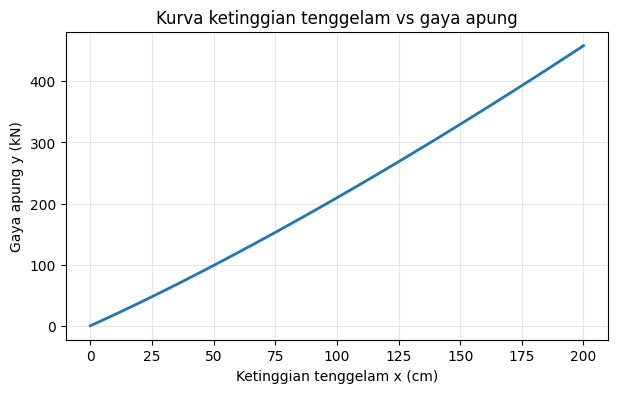

In [3]:
d_arr = np.linspace(0, H, 201)
F_arr = np.array([rho*g*V(d) for d in d_arr])

plt.figure(figsize=(7,4))
plt.plot(d_arr*100, F_arr, lw=2)
plt.xlabel("Ketinggian tenggelam x (cm)")
plt.ylabel("Gaya apung y (kN)")
plt.title("Kurva ketinggian tenggelam vs gaya apung")
plt.grid(alpha=.3)
plt.show()

## Soal 3 Center of buoyancy (dari lantai kapal)



In [9]:
def ybar_B(d):
    return quad(lambda y: y*Lp(y), 0, d)[0] / quad(Lp, 0, d)[0]

y_haluan  = 4/3
y_tengah  = 1.0
y_buritan = 2 - 4*b/(3*np.pi)
yB_analitik = (V_haluan*y_haluan + V_tengah*y_tengah + V_buritan*y_buritan)/V_analitik

print(f"CoB analitik = {yB_analitik*100:.2f} cm")
print(f"CoB numerik  = {ybar_B(H)*100:.2f} cm  {round(ybar_B(H)*100)} cm dari lantai kapal")

CoB analitik = 105.81 cm
CoB numerik  = 105.81 cm  106 cm dari lantai kapal


## Soal 4 Massa total kapal (baja 160 kg/m²)

In [5]:
A_dek    = W*(Lbow+Lmid+a)
A_dasar  = W*Lmid
A_sisi   = 2*quad(Lp, 0, H)[0]
A_slope  = W*np.hypot(Lbow, H)
busur    = quad(lambda p: np.sqrt((a*np.sin(p))**2 + (b*np.cos(p))**2), 0, np.pi/2)[0]
A_buritan = W*busur
A_total  = A_dek + A_dasar + A_sisi + A_slope + A_buritan

M_baja = sigma*A_total      # ton
print(f"Luas dek       = {A_dek:.3f} m2")
print(f"Luas dasar     = {A_dasar:.3f} m2")
print(f"Luas 2 sisi    = {A_sisi:.3f} m2")
print(f"Luas haluan    = {A_slope:.3f} m2")
print(f"Luas buritan   = {A_buritan:.3f} m2 (busur {busur:.4f} m)")
print(f"Luas total     = {A_total:.3f} m2")
print(f"Massa kapal    = {M_baja*1000:.1f} kg = {M_baja:.3f} ton")

Luas dek       = 27.000 m2
Luas dasar     = 18.000 m2
Luas 2 sisi    = 31.142 m2
Luas haluan    = 8.485 m2
Luas buritan   = 7.266 m2 (busur 2.4221 m)
Luas total     = 91.893 m2
Massa kapal    = 14702.9 kg = 14.703 ton


## Soal 5 Kedalaman kapal tenggelam dengan muatan


In [10]:
def sarat(M_total):
    if M_total > rho*Vmax:
        return None
    return brentq(lambda d: rho*V(d) - M_total, 1e-9, H)

M_tot = M_baja + M_c
print(f"M total = {M_tot:.3f} ton ; kapasitas apung maks = {rho*Vmax:.3f} ton")
d_sat = sarat(M_tot)
if d_sat is None:
    print(" M total > daya apung maksimum: kapal TENGGELAM TOTAL (sarat > 2 m).")
    print(f"   Kekurangan daya apung = {M_tot-rho*Vmax:.2f} ton")
else:
    print(f"Sarat = {d_sat*100:.1f} cm")

M total = 3514.703 ton ; kapasitas apung maks = 46.712 ton
 M total > daya apung maksimum: kapal TENGGELAM TOTAL (sarat > 2 m).
   Kekurangan daya apung = 3467.99 ton


## Soal 6 Kurva ketinggian dari lantai kapal (x) vs massa akumulatif (y)

Cek: massa baja kumulatif di y=2 -> 14.703 ton (harus 14.703)


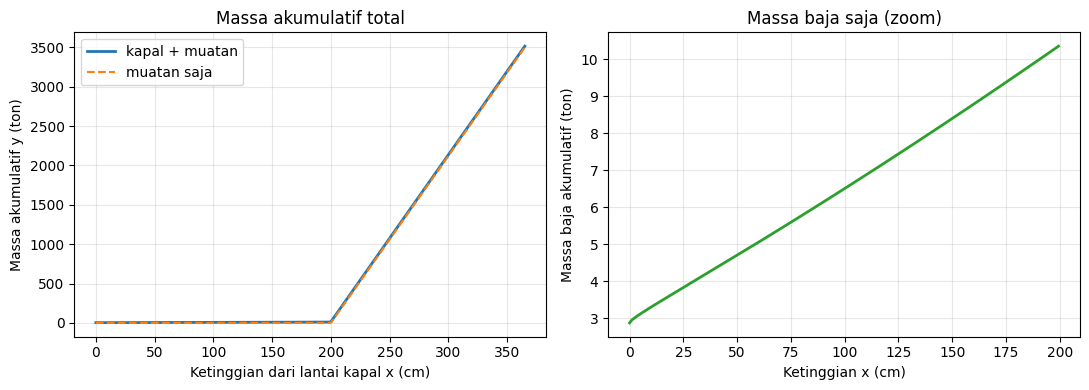

In [7]:
def busur_hingga(y):       # panjang busur buritan dari y=0 sampai y
    if y <= 0: return 0.0
    phi_y = np.arcsin(np.clip((2-y)/b, -1, 1))        # y = 2 - b sin(phi)
    return quad(lambda p: np.sqrt((a*np.sin(p))**2+(b*np.cos(p))**2), phi_y, np.pi/2)[0]

def massa_baja_kum(y):
    y = min(y, H)
    m = A_dasar                                       # dasar (di y=0)
    m += 2*quad(Lp, 0, y)[0] + W*np.sqrt(2)*y + W*busur_hingga(y)
    if y >= H: m += A_dek                             # dek (di y=2)
    return sigma*m

def massa_muatan_kum(y):
    return M_c*np.clip((y-H)/h_c, 0, 1)

y_arr = np.linspace(0, H+h_c, 400)
ms = np.array([massa_baja_kum(y) for y in y_arr])
mc = np.array([massa_muatan_kum(y) for y in y_arr])
mt = ms + mc
print(f"Cek: massa baja kumulatif di y=2 -> {massa_baja_kum(H):.3f} ton (harus {M_baja:.3f})")

fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(y_arr*100, mt, lw=2, label="kapal + muatan")
ax[0].plot(y_arr*100, mc, '--', label="muatan saja")
ax[0].set_xlabel("Ketinggian dari lantai kapal x (cm)"); ax[0].set_ylabel("Massa akumulatif y (ton)")
ax[0].set_title("Massa akumulatif total"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(y_arr[y_arr<=H]*100, ms[y_arr<=H], lw=2, color="C2")
ax[1].set_xlabel("Ketinggian x (cm)"); ax[1].set_ylabel("Massa baja akumulatif (ton)")
ax[1].set_title("Massa baja saja (zoom)"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Soal 7 Center of mass (kapal + muatan)

In [8]:
mom_dek    = A_dek*2
mom_dasar  = 0.0
mom_sisi   = 2*quad(lambda y: y*Lp(y), 0, H)[0]
mom_slope  = W*np.sqrt(2)*quad(lambda y: y, 0, H)[0]
mom_buritan= W*quad(lambda p: (2-b*np.sin(p))*np.sqrt((a*np.sin(p))**2+(b*np.cos(p))**2), 0, np.pi/2)[0]
y_baja = (mom_dek+mom_dasar+mom_sisi+mom_slope+mom_buritan)/A_total

y_muatan = H + h_c/2
y_CM = (M_baja*y_baja + M_c*y_muatan)/(M_baja+M_c)

print(f"CoM baja saja     = {y_baja*100:.1f} cm")
print(f"CoM muatan        = {y_muatan*100:.1f} cm")
print(f"CoM kapal+muatan  = {y_CM*100:.1f} cm  -> {round(y_CM*100)} cm dari lantai kapal")

y_CM_alt = (M_baja*y_baja + M_c_alt*y_muatan)/(M_baja+M_c_alt)
print(f"[Pembanding muatan 100 kg-per-NPM] CoM = {y_CM_alt*100:.1f} cm")

CoM baja saja     = 110.7 cm
CoM muatan        = 282.5 cm
CoM kapal+muatan  = 281.8 cm  -> 282 cm dari lantai kapal


NameError: name 'M_c_alt' is not defined